In [56]:
import pandas_datareader.data as web

In [57]:
from datetime import datetime, timedelta
from statsmodels.tsa.statespace.varmax import VARMAX
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import grangercausalitytests, adfuller

In [58]:
filepath = 'https://raw.githubusercontent.com/selva86/datasets/master/Raotbl6.csv'
macro_data = pd.read_csv(filepath, parse_dates=['date'], index_col='date')
print(macro_data.shape)  # (123, 8)
macro_data.head()

(123, 8)


,rgnp,pgnp,ulc,gdfco,gdf,gdfim,gdfcf,gdfce
date,,,,,,,,
1959-01-01,1606.4,1608.3,47.5,36.9,37.4,26.9,32.3,23.1
1959-04-01,1637.0,1622.2,47.5,37.4,37.5,27.0,32.2,23.4
1959-07-01,1629.5,1636.2,48.7,37.6,37.6,27.1,32.4,23.4
1959-10-01,1643.4,1650.3,48.8,37.7,37.8,27.1,32.5,23.8
1960-01-01,1671.6,1664.6,49.1,37.8,37.8,27.2,32.4,23.8


In [59]:
data = macro_data.reset_index(drop=True)
#data = macro_data.drop(columns = ['date'])
#data.head()
# Calculate returns
returns = data.pct_change().dropna()


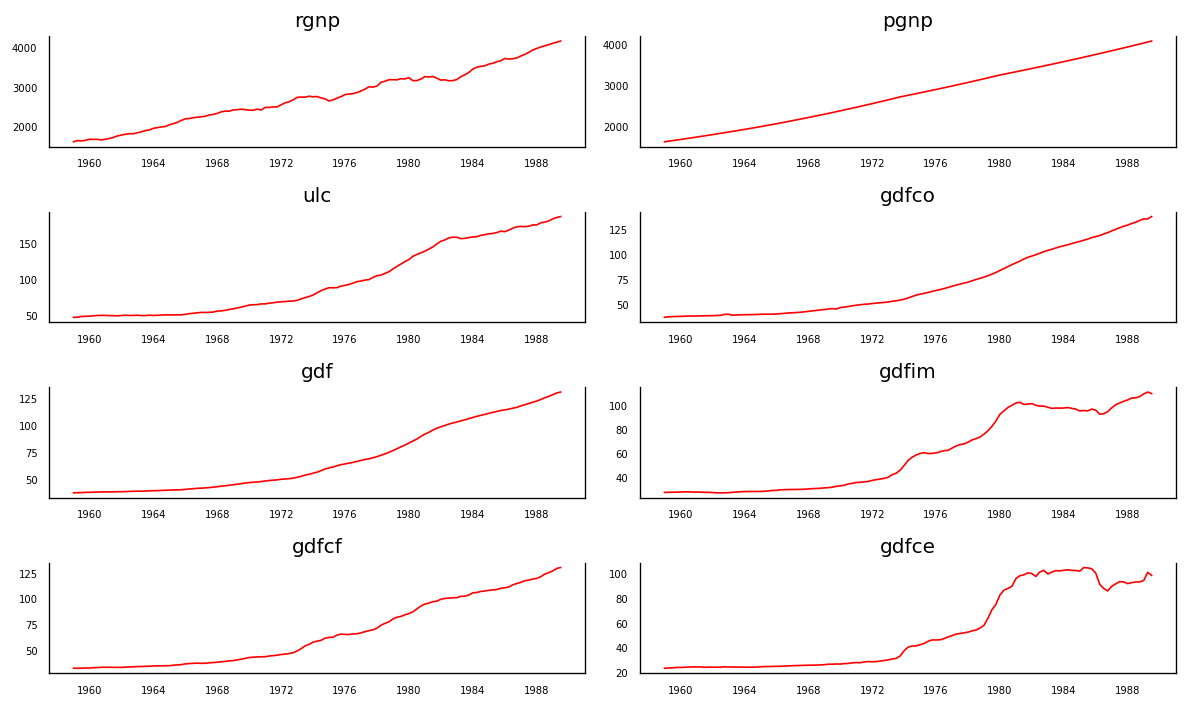

In [60]:
fig, axes = plt.subplots(nrows=4, ncols=2, dpi=120, figsize=(10,6))
for i, ax in enumerate(axes.flatten()):
    data = macro_data[macro_data.columns[i]]
    ax.plot(data, color='red', linewidth=1)
    # Decorations
    ax.set_title(macro_data.columns[i])
    ax.xaxis.set_ticks_position('none')
    ax.yaxis.set_ticks_position('none')
    ax.spines["top"].set_alpha(0)
    ax.tick_params(labelsize=6)

plt.tight_layout();

rgnp - Real gross national product
pgnp - Potential gross national product
ulc - Labour cost

First need to check whether the time series is stationary or not

In [61]:
ad_fuller_result_1 = adfuller(macro_data['rgnp'])

print('realgdp')
print(f'ADF Statistic: {ad_fuller_result_1[0]}')
print(f'p-value: {ad_fuller_result_1[1]}')

print('\n---------------------\n')

ad_fuller_result_2 = adfuller(macro_data['ulc'])

print('realcons')
print(f'ADF Statistic: {ad_fuller_result_2[0]}')
print(f'p-value: {ad_fuller_result_2[1]}')

realgdp
ADF Statistic: 0.6418816546694828
p-value: 0.9886037114305949

---------------------

realcons
ADF Statistic: 1.3967161828616623
p-value: 0.9970991728829679


/var/folders/75/tzhl6qbj2_d5s735f0nmbxcr0000gn/T/ipykernel_1641/3145199099.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  ad_fuller_result_1 = adfuller(macro_data['rgnp'])
/var/folders/75/tzhl6qbj2_d5s735f0nmbxcr0000gn/T/ipykernel_1641/3145199099.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  ad_fuller_result_2 = adfuller(macro_data['ulc'])


since both p-values are > 0.05, these are non-stationary

In [62]:
#now to make stationary use diff()
ad_fuller_result_1 = adfuller(macro_data['rgnp'].diff()[1:])

print('realgdp')
print(f'ADF Statistic: {ad_fuller_result_1[0]}')
print(f'p-value: {ad_fuller_result_1[1]}')

print('\n---------------------\n')

ad_fuller_result_2 = adfuller(macro_data['ulc'].diff()[1:])

print('realcons')
print(f'ADF Statistic: {ad_fuller_result_2[0]}')
print(f'p-value: {ad_fuller_result_2[1]}')

realgdp
ADF Statistic: -5.427594381007333
p-value: 2.9633019848469254e-06

---------------------

realcons
ADF Statistic: -3.576080473150911
p-value: 0.006235131830238172


/var/folders/75/tzhl6qbj2_d5s735f0nmbxcr0000gn/T/ipykernel_1641/1836298007.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  ad_fuller_result_1 = adfuller(macro_data['rgnp'].diff()[1:])
/var/folders/75/tzhl6qbj2_d5s735f0nmbxcr0000gn/T/ipykernel_1641/1836298007.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  ad_fuller_result_2 = adfuller(macro_data['ulc'].diff()[1:]

In [63]:
# Use optimal lag order to run Granger Causality test
from statsmodels.tsa.api import VAR

# Create a dataset to run the VAR model
gc_data = returns[["rgnp","ulc"]]

# Use select_order to find the optimal lag order
model = VAR(gc_data)
lag_order_results = model.select_order(maxlags=10)
lag_order = lag_order_results.aic # You can also use bic, fpe or hqic
print('Optimal Lag Order:', lag_order)

Optimal Lag Order: 4


/Users/aadritanandi/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)


In [64]:
# Fit the VAR model
model_fitted = model.fit(lag_order)

In [65]:
# Perform Granger causality test on JPMorgan Granger causes Technology; the test statistic is F-test
test_result = model_fitted.test_causality(caused='rgnp', causing='ulc',kind='f')
print(test_result.summary())

Granger causality F-test. H_0: ulc does not Granger-cause rgnp. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
         7.908          2.413   0.000 (4, 218)
----------------------------------------------


In [66]:
# Perform Granger causality test on Technology Granger causes JPMorgan; the test statistic is F-test
test_result = model_fitted.test_causality(caused='ulc', causing='rgnp',kind='f')
print(test_result.summary())

Granger causality F-test. H_0: rgnp does not Granger-cause ulc. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
         10.17          2.413   0.000 (4, 218)
----------------------------------------------


In [67]:
macro_data = macro_data[['ulc', 'rgnp']]


In [68]:
train_df = macro_data[: -12]
test_df = macro_data[-12:]

In [69]:
model = VAR(train_df.diff()[1:])

/Users/aadritanandi/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


In [70]:
sorted_order = model.select_order(maxlags =20)
print(sorted_order.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        6.778       6.834       878.3       6.800
1        5.988      6.154*       398.5       6.055
2        5.942       6.220       380.9       6.054
3        5.933       6.322       377.4       6.090
4       5.793*       6.293      328.5*      5.995*
5        5.873       6.484       356.3       6.120
6        5.828       6.550       341.1       6.119
7        5.894       6.727       365.0       6.230
8        5.890       6.835       364.8       6.271
9        5.942       6.998       385.8       6.368
10       5.930       7.097       382.9       6.401
11       5.913       7.191       378.5       6.428
12       5.885       7.274       370.7       6.445
13       5.925       7.424       388.6       6.529
14       5.882       7.493       376.0       6.532
15       5.950       7.672       406.9       6.644
16       5.933       7.766     

In [73]:
var_model = VARMAX(train_df, order = (4,0), enforce_stationarity = True)
fitted_model = var_model.fit(disp = False)
print(fitted_model.summary())

/Users/aadritanandi/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/Users/aadritanandi/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                           Statespace Model Results                           
Dep. Variable:        ['ulc', 'rgnp']   No. Observations:                  111
Model:                         VAR(4)   Log Likelihood              -11823.885
                          + intercept   AIC                          23689.770
Date:                Thu, 22 Oct 2026   BIC                          23746.670
Time:                        21:05:10   HQIC                         23712.853
Sample:                    01-01-1959                                         
                         - 07-01-1986                                         
Covariance Type:                  opg                                         
Ljung-Box (L1) (Q):          36.51, 106.07   Jarque-Bera (JB):         22.59, 13.79
Prob(Q):                        0.00, 0.00   Prob(JB):                   0.00, 0.00
Heteroskedasticity (H):         1.69, 0.27   Skew:                      0.68, -0.86
Prob(H) (two-sided):            0.12,

In [74]:
n_forecast = 12
predict = fitted_model.get_prediction(start = len(train_df), end = len(train_df)+ n_forecast)
predictions = predict.predicted_mean

In [ ]:
predictions.